# Exploratory Data Analysis: Retail Customer Sales Data

**Data Analyst Training Program: Mini Project 1**

**Name:** Abhishek Sharma  |  **ID:** 2026M01410110

**Goal:** Understand, audit, clean and profile the retail sales dataset (7,000+ transactions, 2023-2024, four regions of India) *before* any dashboards or statistical tests are built on it.

**Plan of this notebook**
1. Setup and first look
2. Data quality audit
3. Data cleaning (every decision explained)
4. Descriptive statistics and univariate analysis
5. Outlier detection
6. Feature engineering and business questions (groupby)
7. Save cleaned data and summary of findings
8. Test cases
9. Fairness check
10. Final conclusion

## 0. Install the libraries (run this cell first)
If a library is missing on your computer, this cell installs it. If everything is already installed, it does nothing.

In [1]:
import importlib.util
import subprocess
import sys

for package in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']:
    if importlib.util.find_spec(package) is None:
        print('Installing', package, '...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package, '-q'])
print('All libraries are ready.')

All libraries are ready.


## 1. Setup and First Look

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11})
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# One consistent colour scheme for the whole notebook
TEAL, AMBER, GREY, BRICK = '#0F766E', '#D98B16', '#9AA39F', '#B4432C'

# Find the main project folder. This works if VS Code starts inside the notebook folder or in the main folder.
import glob
found = [p for p in ['.', '..'] if os.path.isdir(p + '/02_Original_Dataset')]
found += [os.path.dirname(p) for p in glob.glob('*/02_Original_Dataset')]
if not found:
    raise FileNotFoundError('Open the main project folder in VS Code and keep the numbered folders as they are.')
ROOT = found[0]
RAW_FILE = ROOT + '/02_Original_Dataset/Abhishek_sharma_2026M01410110_Original_Dataset.csv'
CLEAN_FILE = ROOT + '/07_Cleaned_Dataset/Abhishek_sharma_2026M01410110_Cleaned_Dataset.csv'
CHARTS_FILE = ROOT + '/09_Charts/Abhishek_sharma_2026M01410110_Charts.pdf'

# Every chart is remembered here with a short caption. All charts are saved as one PDF near the end.
CHARTS = []
def keep_chart(caption):
    CHARTS.append((plt.gcf(), caption))

raw = pd.read_csv(RAW_FILE)   # untouched copy; I never edit this
print('Shape (rows, columns):', raw.shape)

Shape (rows, columns): (7084, 24)


In [3]:
print(raw.dtypes)

Transaction_ID            str
Customer_ID               str
Order_Date                str
Delivery_Date             str
Age                   float64
Gender                    str
Income                float64
Region                    str
State                     str
City                      str
Customer_Segment          str
Product_Category          str
Product                   str
Quantity                int64
Unit_Price            float64
Discount              float64
Sales                 float64
Cost                  float64
Profit                float64
Payment_Method            str
Delivery_Mode             str
Customer_Rating       float64
Satisfaction_Level        str
Returned                  str
dtype: object


In [4]:
display(raw.head())
display(raw.tail())

  Transaction_ID Customer_ID  Order_Date Delivery_Date   Age  Gender    Income Region      State      City Customer_Segment Product_Category        Product  Quantity  Unit_Price  Discount     Sales      Cost   Profit Payment_Method Delivery_Mode  Customer_Rating Satisfaction_Level Returned
0      TXN205933   CUST10816  2023-12-19    2023-12-25 38.00    Male 62,828.52   West    Gujarat     Surat         Consumer          Grocery      Honey Jar         3      887.94      0.32  1,811.40  1,204.47   606.93     Debit Card      Standard             3.00                Low       No
1      TXN201247   CUST10916  2023-09-30    2023-10-04 42.00    Male 50,952.64  North    Haryana  Gurugram      Home Office      Electronics      USB-C Hub         2   14,309.96      0.18 23,468.33 17,137.06 6,331.27    Credit Card      Standard             3.00               High       No
2      TXN202714   CUST11352  2023-01-12    2023-01-20 41.00    Male 60,476.00   East  Jharkhand    Ranchi         Consumer    

**First impression:** 7,084 rows and 24 columns. Date columns are read as plain text (`str`), which already hints that the date formats need work. `Age`, `Income`, `Discount`, `Customer_Rating` are numeric but contain missing values.

## 2. Data Quality Audit
I look for six kinds of problems: missing values, duplicates, inconsistent categories, impossible values, extreme values, and date problems.

### 2.1 Missing values

                    missing_count  missing_%
Customer_Rating               428       6.04
Income                        253       3.57
Satisfaction_Level            179       2.53
Age                           142       2.00
Delivery_Date                 106       1.50
Discount                       71       1.00


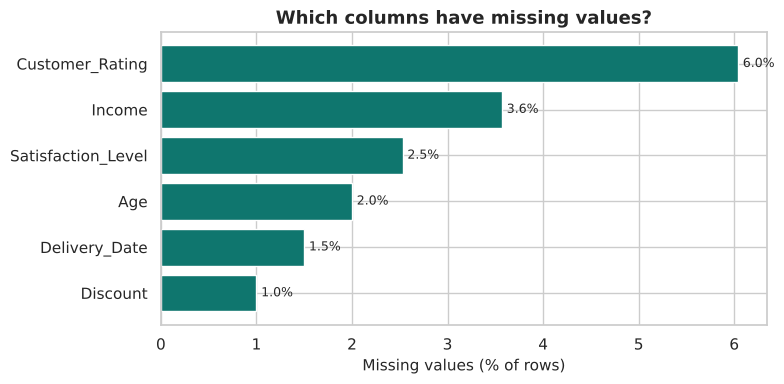

In [5]:
missing = pd.DataFrame({'missing_count': raw.isna().sum(),
                        'missing_%': (raw.isna().mean() * 100).round(2)})
missing = missing[missing.missing_count > 0].sort_values('missing_count', ascending=False)
display(missing)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(missing.index[::-1], missing['missing_%'][::-1], color=TEAL)
for i, v in enumerate(missing['missing_%'][::-1]):
    ax.text(v + 0.05, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlabel('Missing values (% of rows)')
ax.set_title('Which columns have missing values?')
plt.tight_layout()
keep_chart('Missing values: which columns have gaps (as % of rows)')
plt.show()

**Reading:** six columns have gaps. `Customer_Rating` is the largest (about 6%), which is natural because not every customer rates an order. The others (`Income`, `Satisfaction_Level`, `Age`, `Delivery_Date`, `Discount`) are data-entry gaps.

### 2.2 Duplicate rows

In [6]:
print('Exact duplicate rows            :', raw.duplicated().sum())
print('Repeated Transaction_ID values  :', raw.Transaction_ID.duplicated().sum())
print('Unique Transaction_IDs          :', raw.Transaction_ID.nunique())

# Transaction_ID should be unique. Some IDs repeat but the rows are not exact copies. Why?
dup_ids = raw[raw.Transaction_ID.duplicated(keep=False)]
not_exact = dup_ids[~dup_ids.duplicated(keep=False)]
print('Rows with repeated ID that are NOT exact copies:', len(not_exact))
display(not_exact.sort_values('Transaction_ID').head(4)[['Transaction_ID', 'Order_Date', 'Gender', 'Region', 'Sales']])

Exact duplicate rows            : 61
Repeated Transaction_ID values  : 84
Unique Transaction_IDs          : 7000
Rows with repeated ID that are NOT exact copies: 46
     Transaction_ID  Order_Date  Gender Region    Sales
1227      TXN200162  22/07/2024  Female  South 3,938.61
1386      TXN200162  2024-07-22  Female  South 3,938.61
3392      TXN200221  2023-06-23  female   West 2,468.85
6761      TXN200221  2023-06-23  Female   West 2,468.85


**Reading:** there are 7,000 real transactions but 7,084 rows, so 84 rows are repeats. 61 are exact copies. The other 23 repeats look different only because of formatting (for example `Order_Date` written as `22/07/2024` in one copy and `2024-07-22` in the other, or `NORTH` vs `North`). So I must **standardise first, then remove duplicates**, otherwise those 23 would slip through.

### 2.3 Inconsistent category labels

In [7]:
print(raw.Gender.value_counts(), '\n')
print(raw.Region.value_counts())

Gender
Female    3585
Male      3232
FEMALE      53
female      53
male        46
MALE        44
M           38
F           33
Name: count, dtype: int64 

Region
West     1783
East     1754
South    1741
North    1647
east       30
south      24
north      21
Sth        20
WEST       19
Nort       17
west       15
NORTH      13
Name: count, dtype: int64


**Reading:** `Gender` has 8 spellings for 2 values (Male, Female, MALE, male, M, ...). `Region` has 12 spellings for 4 regions, including typos `Nort` and `Sth`. Left alone, any group-by would split one region into many.

### 2.4 Impossible and out-of-range values

In [8]:
bad_age = raw[(raw.Age <= 0) | (raw.Age > 100)]
bad_disc = raw[(raw.Discount < 0) | (raw.Discount > 0.5)]
print('Impossible Age values (<=0 or >100):', len(bad_age), '->', sorted(bad_age.Age.tolist()))
print('Invalid Discount values (<0 or >0.5):', len(bad_disc), '->', sorted(bad_disc.Discount.tolist()))
print()
print('Age range of the remaining rows    :', raw.Age[(raw.Age > 0) & (raw.Age <= 100)].min(), 'to', raw.Age[(raw.Age > 0) & (raw.Age <= 100)].max())
print('Quantity range                     :', raw.Quantity.min(), 'to', raw.Quantity.max())
print('Rows with Unit_Price <= 0 or Sales <= 0:', ((raw.Unit_Price <= 0) | (raw.Sales <= 0)).sum())
print('Rows where Profit != Sales - Cost  :', ((raw.Profit - (raw.Sales - raw.Cost)).abs() > 0.02).sum())

Impossible Age values (<=0 or >100): 6 -> [-12.0, -5.0, -1.0, 150.0, 180.0, 999.0]
Invalid Discount values (<0 or >0.5): 6 -> [-0.2, -0.1, 1.1, 1.2, 1.5, 2.0]

Age range of the remaining rows    : 18.0 to 72.0
Quantity range                     : 1 to 10
Rows with Unit_Price <= 0 or Sales <= 0: 0
Rows where Profit != Sales - Cost  : 0


**Reading:** 6 impossible ages (negative, or 150 to 999 years) and 6 invalid discounts (negative, or above 100%). The data dictionary says Discount must be between 0 and 0.5. Profit is always exactly Sales minus Cost, so the money columns are internally consistent.

### 2.5 Extreme Income values

In [9]:
print(raw.Income.describe())
print('\nTop 10 incomes:')
print(raw.Income.nlargest(10).round(0).tolist())

# Income is a property of the customer, so it should not change between a customer's orders
inc_per_cust = raw.groupby('Customer_ID').Income.agg(['min', 'max', 'nunique'])
changing = inc_per_cust[inc_per_cust['nunique'] > 1]
print('\nCustomers whose Income differs between their own orders:', len(changing))
display(changing)

count       6,831.00
mean       55,023.81
std        37,183.43
min        15,000.00
25%        37,057.03
50%        48,897.51
75%        65,395.97
max     1,750,890.41
Name: Income, dtype: float64

Top 10 incomes:
[1750890.0, 721082.0, 622290.0, 606985.0, 598321.0, 595874.0, 473562.0, 412792.0, 333322.0, 286876.0]

Customers whose Income differs between their own orders: 9
                   min          max  nunique
Customer_ID                                 
CUST10006    51,802.91   622,289.57        2
CUST10144    32,295.76   412,791.60        2
CUST10285    55,607.45   595,873.84        2
CUST10770    45,699.65   606,984.57        2
CUST10854    66,630.88   721,081.66        2
CUST10946    26,372.37   333,322.44        2
CUST11124   118,558.79 1,750,890.41        2
CUST11171    35,032.79   473,561.95        2
CUST11202    57,377.64   598,321.39        2


**Reading:** the median income is about 49,000 but the maximum is 17.5 lakh. The same customer is recorded with a normal income in one order and a huge one in another (for example 51,803 vs 622,290). A person's income cannot jump 10x between two purchases, so these look like **data-entry errors** (extra digit or wrong scale), not rich customers.

### 2.6 Date format problems

In [10]:
def date_pattern(s):
    s = s.dropna().astype(str)
    return (s.str.replace(r'\d', '9', regex=True)
             .str.replace(r'[A-Za-z]{3}', 'Mon', regex=True))

print('Order_Date formats:')
print(date_pattern(raw.Order_Date).value_counts(), '\n')
print('Delivery_Date formats:')
print(date_pattern(raw.Delivery_Date).value_counts())

Order_Date formats:
Order_Date
9999-99-99     6601
99-Mon-9999     161
99/99/9999      161
99-99-9999      161
Name: count, dtype: int64 

Delivery_Date formats:
Delivery_Date
9999-99-99     6509
99-Mon-9999     158
99/99/9999      156
99-99-9999      155
Name: count, dtype: int64


**Reading:** four different formats are mixed: `2023-12-19`, `19/12/2023`, `12-19-2023` and `19-Dec-2023`. The slash style is **day/month/year** and the dash style with numbers is **month-day-year** (I confirm this below, because `02-09-2023` could be read two ways).

In [11]:
def parse_mixed_date(s):
    """Parse a column that mixes four date formats into one datetime column."""
    s = s.astype('string').str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    rules = [(r'^\d{4}-\d{2}-\d{2}$',   '%Y-%m-%d'),   # 2023-12-19
             (r'^\d{2}/\d{2}/\d{4}$',   '%d/%m/%Y'),   # 19/12/2023  (day first)
             (r'^\d{2}-\d{2}-\d{4}$',   '%m-%d-%Y'),   # 12-19-2023  (month first)
             (r'^\d{2}-[A-Za-z]{3}-\d{4}$', '%d-%b-%Y')] # 19-Dec-2023
    for pattern, fmt in rules:
        m = s.str.match(pattern).fillna(False).astype(bool)
        out[m] = pd.to_datetime(s[m], format=fmt, errors='coerce')
    return out

order_dt = parse_mixed_date(raw.Order_Date)
deliv_dt = parse_mixed_date(raw.Delivery_Date)

# Proof that my reading of the formats is right:
# 1) every date must parse and fall inside 2023-2024
print('Order_Date not parsed          :', order_dt.isna().sum())
print('Order_Date range               :', order_dt.min().date(), 'to', order_dt.max().date())
# 2) duplicate copies of the same transaction (written in different formats) must agree
chk = pd.DataFrame({'id': raw.Transaction_ID, 'd': order_dt})
chk = chk[chk.id.duplicated(keep=False)].groupby('id').d.nunique()
print('Duplicate IDs whose copies disagree on date:', (chk > 1).sum(), '(0 means our format rules are correct)')

days = (deliv_dt - order_dt).dt.days
print('\nDelivery_Days summary:')
print(days.describe())
print('Delivered BEFORE ordered (negative days):', (days < 0).sum())

Order_Date not parsed          : 0
Order_Date range               : 2023-01-01 to 2024-12-31
Duplicate IDs whose copies disagree on date: 0 (0 means our format rules are correct)

Delivery_Days summary:
count   6,978.00
mean        5.64
std         2.84
min        -4.00
25%         4.00
50%         6.00
75%         8.00
max        17.00
dtype: float64
Delivered BEFORE ordered (negative days): 15


**Reading:** all dates parse and stay inside 2023-2024, and duplicate copies agree on the date, so my format rules are correct. Delivery normally takes 4 to 8 days (maximum 17), but 15 orders show a delivery date *earlier* than the order date. That is impossible, so these are errors.

## 3. Data Cleaning
I clean a **copy** called `df` and keep `raw` untouched. Every decision is written down in `cleaning_log` so it can be shown in the report. Order matters: I standardise labels and dates **first**, and remove duplicates **after**, so that look-alike duplicates become exact copies.

### 3.1 Standardise Gender and Region

In [12]:
df = raw.copy()
cleaning_log = []

gender_map = {'male': 'Male', 'm': 'Male', 'female': 'Female', 'f': 'Female'}
region_map = {'north': 'North', 'nort': 'North', 'south': 'South', 'sth': 'South',
              'east': 'East', 'west': 'West'}

df['Gender'] = df.Gender.str.strip().str.lower().map(gender_map)
df['Region'] = df.Region.str.strip().str.lower().map(region_map)

print('Unmapped Gender:', df.Gender.isna().sum(), '| Unmapped Region:', df.Region.isna().sum())
print(df.Gender.value_counts().to_dict())
print(df.Region.value_counts().to_dict())
cleaning_log.append(('Gender / Region', '8 and 12 spellings', 'Mapped to 2 and 4 standard labels', 'Same value written differently; mapping loses no information'))

Unmapped Gender: 0 | Unmapped Region: 0
{'Female': 3724, 'Male': 3360}
{'West': 1817, 'South': 1785, 'East': 1784, 'North': 1698}


### 3.2 Convert dates to proper datetime

In [13]:
df['Order_Date'] = parse_mixed_date(raw.Order_Date)
df['Delivery_Date'] = parse_mixed_date(raw.Delivery_Date)
print(df[['Order_Date', 'Delivery_Date']].dtypes)

# Delivery before order is impossible. I do not guess the right date, so I set it to missing and flag it.
bad_delivery = df.Delivery_Date < df.Order_Date
df['Delivery_Date_Fixed'] = bad_delivery
df.loc[bad_delivery, 'Delivery_Date'] = pd.NaT
print('Delivery dates earlier than order date, set to missing:', bad_delivery.sum())
cleaning_log.append(('Order_Date / Delivery_Date', '4 mixed formats; 15 deliveries before order', 'Parsed to datetime; 15 bad delivery dates set to missing and flagged', 'Real delivery date is unknown, so inventing one would be worse than leaving it blank'))

Order_Date       datetime64[ns]
Delivery_Date    datetime64[ns]
dtype: object
Delivery dates earlier than order date, set to missing: 15


### 3.3 Remove duplicates

In [14]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Rows before: {before:,}  |  rows after: {len(df):,}  |  removed: {before - len(df)}')
print('Transaction_ID is now unique:', df.Transaction_ID.is_unique)
cleaning_log.append(('Duplicate rows', '84 repeated rows (61 exact, 23 formatting-only)', 'Dropped, kept first copy', 'A transaction must appear once; double counting would inflate Sales and Profit'))

Rows before: 7,084  |  rows after: 7,000  |  removed: 84
Transaction_ID is now unique: True


After standardising, all 84 repeats became exact copies, so one `drop_duplicates()` removed them and every `Transaction_ID` is unique.

### 3.4 Age: impossible values and missing values
**Idea:** a customer's age does not change between orders (I checked: every customer has exactly one age in the data). So instead of filling with a general average, I copy the age from the **same customer's other orders**.

In [15]:
age_valid = df.Age.between(18, 100)
print('Rows with impossible age:', ((df.Age.notna()) & ~age_valid).sum(), '| missing age:', df.Age.isna().sum())

df.loc[~age_valid, 'Age'] = np.nan                     # impossible -> treat as missing
df['Age_Imputed'] = df.Age.isna()                      # flag every row I fill
age_from_customer = df.groupby('Customer_ID').Age.transform('median')
df['Age'] = df.Age.fillna(age_from_customer)           # 1st choice: same customer
still_missing = df.Age.isna().sum()
df['Age'] = df.Age.fillna(df.Age.median())             # last resort: overall median
print('Filled from same customer:', df.Age_Imputed.sum() - still_missing, '| filled with overall median:', still_missing)
print('Age range now:', df.Age.min(), 'to', df.Age.max())
cleaning_log.append(('Age', '6 impossible (-12 to 999) + 142 missing', 'Impossible -> missing; filled from the same customer, flagged in Age_Imputed', 'Age is constant per customer, so this is exact, not a guess'))

Rows with impossible age: 6 | missing age: 140
Filled from same customer: 146 | filled with overall median: 0
Age range now: 18.0 to 72.0


### 3.5 Income: extreme errors and missing values
**Idea:** income is also constant per customer. The 9 giant incomes belong to customers who show a normal income in their other order, so the giant value is the error. I replace the error with the customer's normal value.

In [16]:
cust_min_income = df.groupby('Customer_ID').Income.transform('min')
income_error = df.Income > 3 * cust_min_income          # far above the same customer's own lowest value
print('Income values far above the same customer\'s other orders:', income_error.sum())
display(df.loc[income_error, ['Customer_ID', 'Income']].assign(Normal_Income=cust_min_income[income_error]))

df.loc[income_error, 'Income'] = np.nan
df['Income_Imputed'] = df.Income.isna()
income_from_customer = df.groupby('Customer_ID').Income.transform('median')
df['Income'] = df.Income.fillna(income_from_customer)
left = df.Income.isna().sum()
seg_median = df.groupby('Customer_Segment').Income.transform('median')
df['Income'] = df.Income.fillna(seg_median)
print('Missing/erroneous incomes:', df.Income_Imputed.sum(), '| recovered from same customer:', df.Income_Imputed.sum() - left, '| filled with segment median:', left)
cleaning_log.append(('Income', '9 extreme errors (up to 17.5 lakh) + 253 missing', 'Errors and gaps filled from the same customer; 6 leftovers with segment median; flagged in Income_Imputed', 'Income is constant per customer; median (not mean) is used because income is right-skewed'))

Income values far above the same customer's other orders: 9
     Customer_ID       Income  Normal_Income
99     CUST10006   622,289.57      51,802.91
747    CUST11202   598,321.39      57,377.64
1723   CUST10854   721,081.66      66,630.88
3767   CUST11171   473,561.95      35,032.79
4202   CUST10144   412,791.60      32,295.76
4597   CUST10770   606,984.57      45,699.65
4765   CUST10285   595,873.84      55,607.45
6296   CUST10946   333,322.44      26,372.37
6850   CUST11124 1,750,890.41     118,558.79
Missing/erroneous incomes: 254 | recovered from same customer: 248 | filled with segment median: 6


### 3.6 Discount: invalid and missing values
**Idea:** the data dictionary says `Sales = Quantity x Unit_Price x (1 - Discount)`. So if Discount is wrong or missing, I can **calculate** it back from the other columns. First I check that this formula really works on the good rows.

In [17]:
implied_discount = (1 - df.Sales / (df.Quantity * df.Unit_Price)).round(2)
good = df.Discount.between(0, 0.5)
print('Formula check on valid rows: max difference =', (implied_discount[good] - df.Discount[good]).abs().max().round(3))

bad_disc = df.Discount.notna() & ~good
print('Invalid discounts:', bad_disc.sum(), '| missing discounts:', df.Discount.isna().sum())
df.loc[bad_disc, 'Discount'] = np.nan
df['Discount_Imputed'] = df.Discount.isna()
df['Discount'] = df.Discount.fillna(implied_discount.clip(0, 0.5))
print('Discount range now:', df.Discount.min(), 'to', df.Discount.max())
cleaning_log.append(('Discount', '6 invalid (-0.2 to 2.0) + 71 missing', 'Recomputed from Sales / (Quantity x Unit_Price); flagged in Discount_Imputed', 'Formula matches recorded discount on valid rows, so the rebuilt value is reliable'))

Formula check on valid rows: max difference = 0.0
Invalid discounts: 6 | missing discounts: 70
Discount range now: 0.0 to 0.5


### 3.7 Rating and Satisfaction: keep the gaps honest

In [18]:
df['Rating_Given'] = df.Customer_Rating.notna()
df['Satisfaction_Level'] = df.Satisfaction_Level.fillna('Not Recorded')
print('Orders without a rating:', (~df.Rating_Given).sum(), f'({(~df.Rating_Given).mean():.1%})')
print(df.Satisfaction_Level.value_counts().to_dict())
cleaning_log.append(('Customer_Rating', '428 missing (6%)', 'Left missing, flag Rating_Given added', 'A rating is the customer\'s opinion; inventing it would create fake satisfaction'))
cleaning_log.append(('Satisfaction_Level', '179 missing', 'Labelled "Not Recorded"', 'Keeps the rows and keeps the gap visible instead of hiding it'))

Orders without a rating: 420 (6.0%)
{'High': 2549, 'Medium': 2518, 'Low': 1758, 'Not Recorded': 175}


### 3.8 Check the cleaned data and show the cleaning log

In [19]:
# Final validation checks
print('Duplicates left          :', df.duplicated().sum())
print('Transaction_ID unique    :', df.Transaction_ID.is_unique)
print('Gender values            :', sorted(df.Gender.unique()))
print('Region values            :', sorted(df.Region.unique()))
print('Age range                :', df.Age.min(), '-', df.Age.max())
print('Discount range           :', df.Discount.min(), '-', df.Discount.max())
print('Max Income               :', round(df.Income.max()))
print('Sales formula max error  :', (df.Sales - df.Quantity * df.Unit_Price * (1 - df.Discount)).abs().max().round(2))
print('Rows x columns           :', df.shape)
print('Missing values left      :')
print(df.isna().sum()[lambda s: s > 0].to_dict())

log = pd.DataFrame(cleaning_log, columns=['Column', 'Problem found', 'Action taken', 'Why'])
pd.set_option('display.max_colwidth', 80)
display(log)

Duplicates left          : 0
Transaction_ID unique    : True
Gender values            : ['Female', 'Male']
Region values            : ['East', 'North', 'South', 'West']
Age range                : 18.0 - 72.0
Discount range           : 0.0 - 0.5
Max Income               : 286876
Sales formula max error  : 0.01
Rows x columns           : (7000, 29)
Missing values left      :
{'Delivery_Date': 120, 'Customer_Rating': 420}
                       Column                                     Problem found                                                                                               Action taken                                                                                        Why
0             Gender / Region                                8 and 12 spellings                                                                          Mapped to 2 and 4 standard labels                               Same value written differently; mapping loses no information
1  Order_Date / Deliv

**Result:** 7,000 clean, unique transactions. Remaining blanks are only `Customer_Rating` (not rated) and `Delivery_Date` (never recorded, or the 15 impossible ones); these are real gaps that I chose not to invent.

## 4. Descriptive Statistics and Univariate Analysis

### 4.1 Descriptive statistics of the key numerical variables

In [20]:
num_cols = ['Age', 'Income', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit']

def full_describe(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return pd.Series({'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
                      'std': s.std(), 'variance': s.var(), 'min': s.min(),
                      'P5': s.quantile(0.05), 'Q1 (25%)': q1, 'Q3 (75%)': q3, 'P95': s.quantile(0.95),
                      'max': s.max(), 'IQR': q3 - q1, 'skewness': s.skew()})

stats = df[num_cols].apply(full_describe).T
display(stats[['mean', 'median', 'mode', 'std', 'variance']])
print()
display(stats[['min', 'P5', 'Q1 (25%)', 'Q3 (75%)', 'P95', 'max', 'IQR', 'skewness']])

                mean    median      mode       std       variance
Age            36.05     36.00     18.00     10.41         108.30
Income     54,245.69 48,754.85 15,000.00 25,787.32 664,985,698.23
Quantity        3.01      3.00      2.00      1.41           1.99
Unit_Price  4,519.23  2,261.47    122.04  4,893.21  23,943,479.34
Discount        0.20      0.18      0.13      0.12           0.01
Sales      10,961.60  4,825.56    258.73 14,549.03 211,674,394.52
Cost        7,371.90  3,229.89    217.28  9,878.00  97,574,874.12
Profit      3,589.70  1,528.70     19.47  4,928.02  24,285,381.42

                 min        P5  Q1 (25%)  Q3 (75%)        P95        max       IQR  skewness
Age            18.00     18.00     29.00     43.00      54.00      72.00     14.00      0.27
Income     15,000.00 23,778.87 37,072.05 65,690.04 101,837.54 286,876.47 28,617.99      1.92
Quantity        1.00      1.00      2.00      4.00       6.00      10.00      2.00      0.73
Unit_Price     51.53    294.23   

**How to read this:**
- For `Age`, mean (36.1) and median (36) are almost the same, so ages are balanced around the middle.
- For `Sales`, `Cost`, `Profit`, `Income`, the **mean is much bigger than the median** (Sales: mean 10,962 vs median 4,826). A few very large orders pull the average up, so the median describes a *typical* order better than the mean.
- Mode is not very meaningful for continuous money columns (almost every value is different); it is useful only for `Quantity` (most common is 2) and for categories.
- Variance is shown for completeness, but the standard deviation is easier to read because it is in the same unit as the data.

### 4.2 Distribution shape of Age, Income, Sales and Profit

{'Age': 0.27, 'Income': 1.92, 'Sales': 2.4, 'Profit': 2.59}


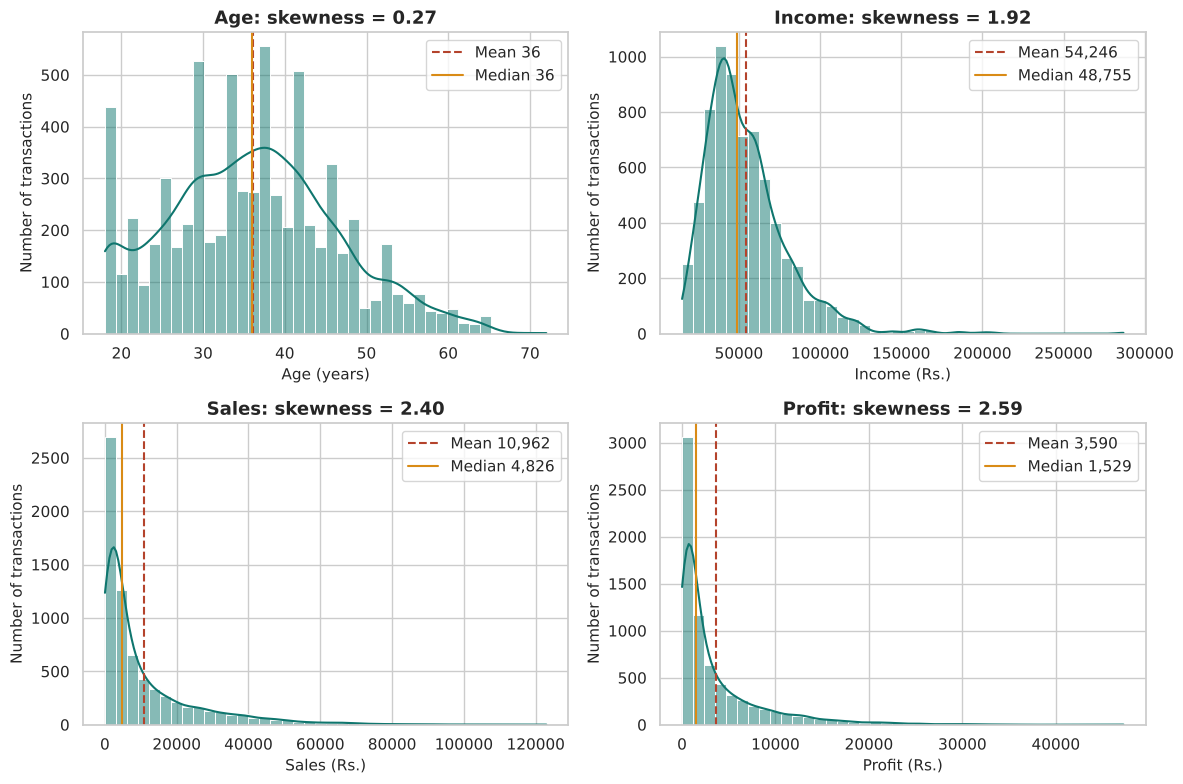

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ['Age', 'Income', 'Sales', 'Profit']):
    sns.histplot(df[col], bins=40, kde=True, color=TEAL, ax=ax)
    ax.axvline(df[col].mean(), color=BRICK, ls='--', lw=1.5, label=f'Mean {df[col].mean():,.0f}')
    ax.axvline(df[col].median(), color=AMBER, ls='-', lw=1.5, label=f'Median {df[col].median():,.0f}')
    ax.set_title(f'{col}: skewness = {df[col].skew():.2f}')
    ax.set_xlabel(col + (' (years)' if col == 'Age' else ' (Rs.)'))
    ax.set_ylabel('Number of transactions')
    ax.legend()
plt.tight_layout()
keep_chart('Shape of Age, Income, Sales and Profit. The mean (red) sits right of the median (amber) when a few large values pull it up.')
plt.show()

print(df[['Age', 'Income', 'Sales', 'Profit']].skew().round(2).to_dict())

**What the shapes mean in business terms:**
- **Age (skew about 0.3): almost symmetric.** Customers are mostly 29 to 43 years old. No special age group dominates.
- **Income (skew about 1.9): right-skewed.** Three quarters of customers earn under about 66,000 a year, but a small group of high earners stretches the right tail.
- **Sales (skew about 2.4) and Profit (skew about 2.6): strongly right-skewed.** Most orders are small (half are below about Rs. 4,800), while a few big Electronics and Furniture orders reach over Rs. 1 lakh. A manager should therefore quote the **median** order as "typical" and treat big orders as a separate group.

### 4.3 Categorical variables: frequency and proportion

Region
        count  share_%
Region                
West     1798    25.70
East     1765    25.20
South    1761    25.20
North    1676    23.90

Product_Category
                  count  share_%
Product_Category                
Electronics        1975    28.20
Grocery            1669    23.80
Clothing           1533    21.90
Furniture           979    14.00
Office Supplies     844    12.10

Customer_Segment
                  count  share_%
Customer_Segment                
Consumer           3840    54.90
Corporate          2114    30.20
Home Office        1046    14.90



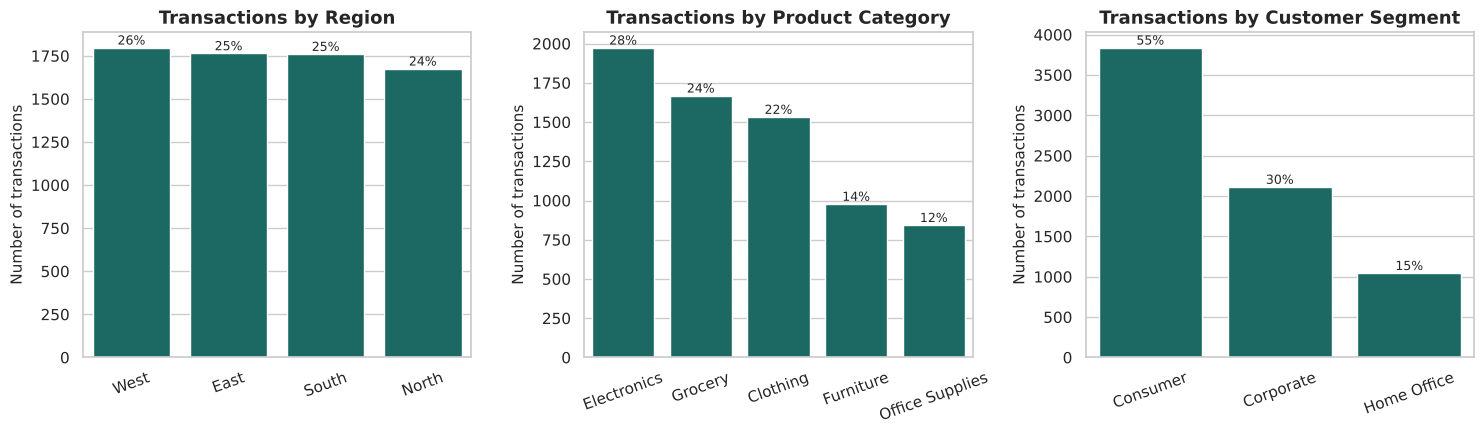

In [22]:
for col in ['Region', 'Product_Category', 'Customer_Segment']:
    t = pd.DataFrame({'count': df[col].value_counts(), 'share_%': (df[col].value_counts(normalize=True) * 100).round(1)})
    print(col); display(t); print()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ['Region', 'Product_Category', 'Customer_Segment']):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color=TEAL, ax=ax)
    for p in ax.patches:
        ax.annotate(f'{p.get_height() / len(df):.0%}', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
    ax.set_title(f'Transactions by {col.replace("_", " ")}')
    ax.set_xlabel('')
    ax.set_ylabel('Number of transactions')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
keep_chart('Number of transactions by region, product category and customer segment')
plt.show()

**Reading:**
- **Region:** the four regions are almost equal (24% to 26% each), so no region is a tiny market.
- **Product category:** Electronics is the most frequent (28%), followed by Grocery (24%) and Clothing (22%). Furniture (14%) and Office Supplies (12%) are the smallest by number of orders.
- **Customer segment:** Consumers make more than half of all orders (55%), Corporate 30%, Home Office 15%.

## 5. Outlier Detection
I use two methods: the **IQR rule** (outside Q1 - 1.5 x IQR and Q3 + 1.5 x IQR) and the **Z-score rule** (more than 3 standard deviations from the mean). Remember that the impossible Age values and the 9 Income errors were already fixed in Section 3, so what remains here is natural variation.

        lower fence  upper fence  IQR outliers  IQR outliers %  Z-score outliers (|z|>3)
Sales    -16,604.37    32,515.17        632.00            9.00                    153.00
Profit    -5,364.72    10,472.09        640.00            9.10                    160.00
Age            8.00        64.00         10.00            0.10                      6.00
Income    -5,854.93   108,617.02        228.00            3.30                     81.00


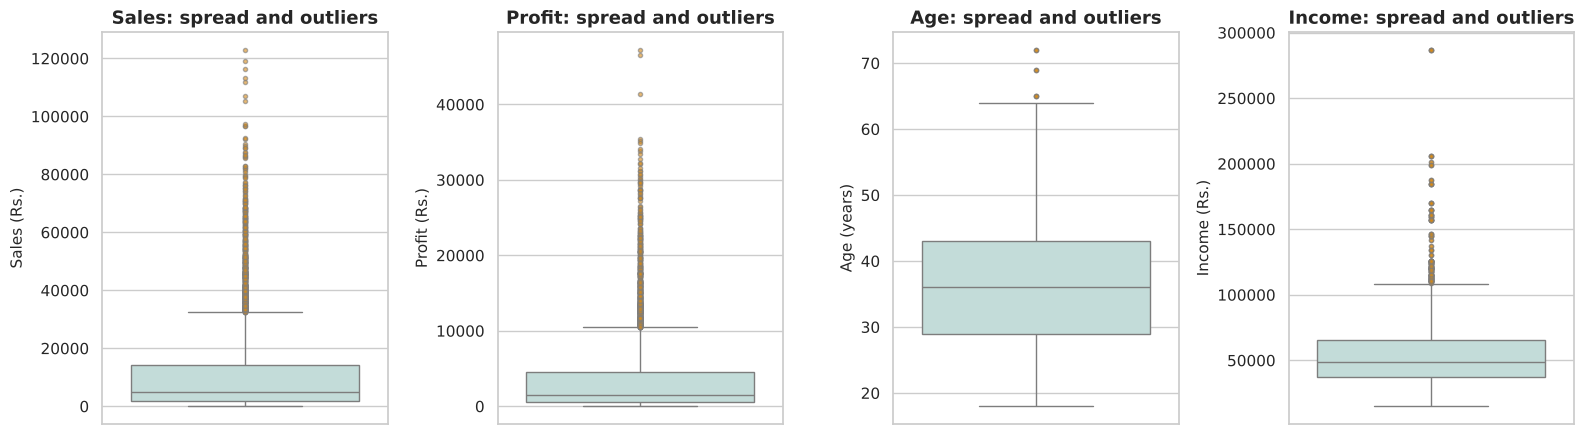

In [23]:
def outlier_report(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return pd.Series({'lower fence': low, 'upper fence': high,
                      'IQR outliers': int(((s < low) | (s > high)).sum()),
                      'IQR outliers %': round(((s < low) | (s > high)).mean() * 100, 1),
                      'Z-score outliers (|z|>3)': int((z.abs() > 3).sum())})

display(df[['Sales', 'Profit', 'Age', 'Income']].apply(outlier_report).T)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, ['Sales', 'Profit', 'Age', 'Income']):
    sns.boxplot(y=df[col], color='#BFE0DC', flierprops=dict(marker='o', markerfacecolor=AMBER, markersize=3, alpha=0.6), ax=ax)
    ax.set_title(f'{col}: spread and outliers')
    ax.set_ylabel(col + (' (years)' if col == 'Age' else ' (Rs.)'))
plt.tight_layout()
keep_chart('Boxplots of Sales, Profit, Age and Income. The dots are outliers by the IQR rule.')
plt.show()

### Are these outliers genuine or errors? Checking the evidence

In [24]:
sales_high = df.Sales > df.Sales.quantile(0.75) + 1.5 * (df.Sales.quantile(0.75) - df.Sales.quantile(0.25))
print('Sales outliers by category (% of that category\'s orders):')
print((df[sales_high].Product_Category.value_counts() / df.Product_Category.value_counts() * 100).round(1).dropna().to_dict())
print('Average Quantity: outlier orders =', df[sales_high].Quantity.mean().round(2), '| all orders =', df.Quantity.mean().round(2))
print('Average Unit_Price: outlier orders =', df[sales_high].Unit_Price.mean().round(0), '| all orders =', df.Unit_Price.mean().round(0))
print('Sales formula still holds for outlier rows (max error):', (df[sales_high].Sales - df[sales_high].Quantity * df[sales_high].Unit_Price * (1 - df[sales_high].Discount)).abs().max().round(2))
print()
print('Age outliers (ages):', sorted(df.Age[(df.Age < 29 - 1.5 * 14) | (df.Age > 43 + 1.5 * 14)].unique().tolist()))
inc_hi = df.Income > df.Income.quantile(0.75) + 1.5 * (df.Income.quantile(0.75) - df.Income.quantile(0.25))
print('Income outliers:', inc_hi.sum(), '| largest income now:', round(df.Income.max()), '| Income outliers that are flagged as imputed:', df[inc_hi].Income_Imputed.sum())

Sales outliers by category (% of that category's orders):
{'Electronics': 16.8, 'Furniture': 30.6}
Average Quantity: outlier orders = 4.39 | all orders = 3.01
Average Unit_Price: outlier orders = 13602.0 | all orders = 4519.0
Sales formula still holds for outlier rows (max error): 0.01

Age outliers (ages): [65.0, 69.0, 72.0]
Income outliers: 228 | largest income now: 286876 | Income outliers that are flagged as imputed: 10


**Decision for each group:**

| Variable | Outliers found | Verdict | Action |
|---|---|---|---|
| **Sales / Profit** | about 9% of orders above roughly Rs. 32,500 (Profit above about Rs. 10,500) | **Genuine.** They are all Electronics or Furniture orders with a high unit price (and often higher quantity), and the Sales formula still holds exactly | Keep. Report medians next to means |
| **Age** | a handful of customers aged about 65 to 72 | **Genuine.** Realistic ages | Keep |
| **Income** | about 3% of rows above roughly Rs. 108,600, max about Rs. 2.9 lakh | **Genuine high earners.** Income is naturally right-skewed, and the 9 *impossible* values (up to Rs. 17.5 lakh) were already corrected in Section 3 | Keep, but use the median income for summaries |
| **Income (before cleaning)** | 9 values from Rs. 3.3 lakh to 17.5 lakh | **Errors.** Same customer had a normal income in another order | Corrected (Section 3.5) |

## 6. Feature Engineering and Business Questions

### 6.1 New calculated columns

In [25]:
# 1) Profit_Margin: how many rupees of profit per rupee of sales
df['Profit_Margin'] = df.Profit / df.Sales

# 2) Delivery_Days: days between order and delivery (missing where the date is missing or was invalid)
df['Delivery_Days'] = (df.Delivery_Date - df.Order_Date).dt.days

# 3) Revenue_per_Customer: total sales of the customer across all their orders
df['Revenue_per_Customer'] = df.groupby('Customer_ID').Sales.transform('sum')

# 4) Orders_per_Customer: how many orders that customer placed
df['Orders_per_Customer'] = df.groupby('Customer_ID').Transaction_ID.transform('count')

# 5) Time parts, for trend analysis
df['Order_Year'] = df.Order_Date.dt.year
df['Order_Month'] = df.Order_Date.dt.to_period('M').astype(str)

# 6) Discount_Band: group the discount into readable ranges
df['Discount_Band'] = pd.cut(df.Discount, bins=[-0.001, 0.10, 0.20, 0.30, 0.50],
                             labels=['0-10%', '10-20%', '20-30%', '30-50%'])

display(df[['Transaction_ID', 'Sales', 'Profit', 'Profit_Margin', 'Delivery_Days', 'Revenue_per_Customer', 'Orders_per_Customer', 'Discount_Band']].head())
print(df[['Profit_Margin', 'Delivery_Days']].describe().round(3))

  Transaction_ID     Sales   Profit  Profit_Margin  Delivery_Days  Revenue_per_Customer  Orders_per_Customer Discount_Band
0      TXN205933  1,811.40   606.93           0.34           6.00              5,003.25                    3        30-50%
1      TXN201247 23,468.33 6,331.27           0.27           4.00             74,411.80                    4        10-20%
2      TXN202714  2,587.86 1,010.03           0.39           8.00            100,342.46                    8         0-10%
3      TXN206797    877.75   320.97           0.37           4.00             29,951.36                    8        30-50%
4      TXN203937  8,328.28 2,799.81           0.34           7.00             21,572.93                    6        20-30%
       Profit_Margin  Delivery_Days
count       7,000.00       6,880.00
mean            0.33           5.66
std             0.07           2.82
min             0.20           1.00
25%             0.27           4.00
50%             0.33           6.00
75%       

**Quick reading:** every order makes a profit (margin between 20% and 45%, typically 33%), and delivery usually takes 4 to 8 days (up to 17).

### 6.2 Correlation heat map

A heat map shows, in one picture, how strongly every pair of numeric columns moves together. Values go from -1 (move in opposite directions) through 0 (no link) to +1 (move together).

       Quantity  Unit_Price  Discount
Sales      0.34        0.92     -0.12


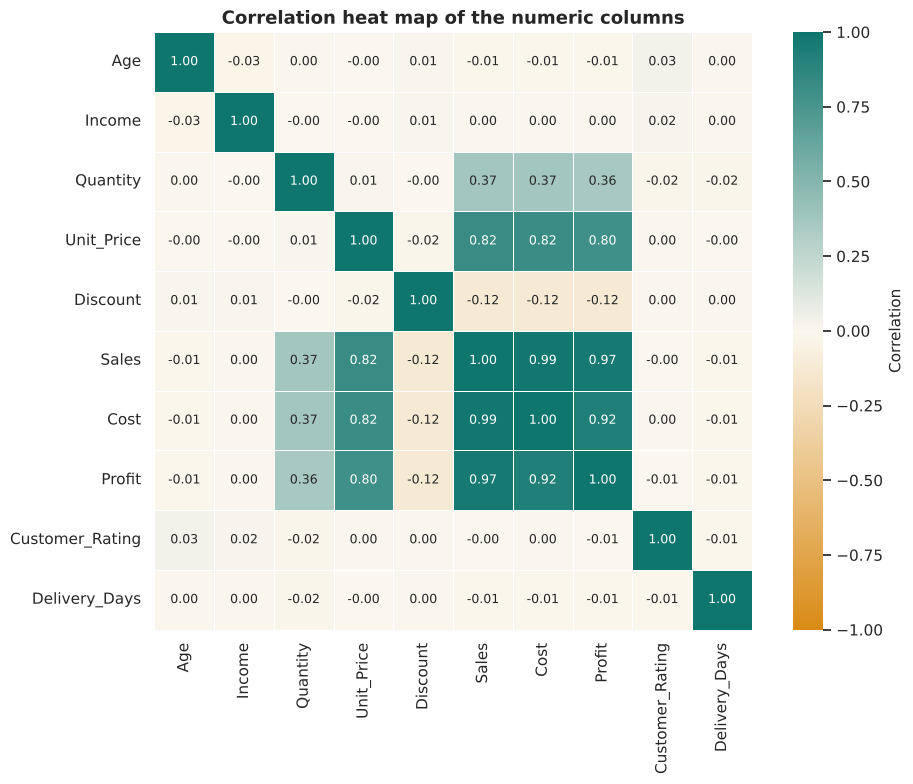

In [26]:
from matplotlib.colors import LinearSegmentedColormap

corr_cols = ['Age', 'Income', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Customer_Rating', 'Delivery_Days']
corr = df[corr_cols].corr()                      # Pearson correlation for every pair of columns

# Amber means a negative link, teal means a positive link, white means no link
teal_amber = LinearSegmentedColormap.from_list('teal_amber', [AMBER, '#FBF7EF', TEAL])

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=teal_amber, vmin=-1, vmax=1, linewidths=0.5,
            square=True, cbar_kws={'label': 'Correlation'}, annot_kws={'size': 9})
plt.title('Correlation heat map of the numeric columns')
plt.tight_layout()
keep_chart('Correlation heat map. Sales, Cost and Profit move together; Unit_Price drives Sales; customer details show almost no link.')
plt.show()

# Spearman (rank based) is less affected by a few very large orders, so I check it too
print(df[corr_cols].corr(method='spearman').loc[['Sales'], ['Quantity', 'Unit_Price', 'Discount']].round(2))

**Reading:**
- **Sales, Cost and Profit move together** (0.92 to 0.99). That is expected, because Cost and Profit are worked out from Sales, so they carry almost the same information.
- **Unit price matters most for Sales** (0.82), then Quantity (0.37). Discount pulls Sales down a little (-0.12).
- **Age, Income, Customer_Rating and Delivery_Days are close to 0 with everything.** Who the customer is (age, income) does not explain how much they spend, and slower delivery does not lower the rating (-0.01).
- A few very large orders can bend a Pearson value. The Spearman check tells the same story, with Unit_Price even stronger (0.92).
- Correlation shows that two columns move together, not that one causes the other.

### 6.3 Business questions using groupby

**Q1. Which region has the highest average order value (AOV)?**

        Orders   Total_Sales  Avg_Order_Value  Median_Order
Region                                                     
East      1765 20,018,192.00        11,342.00      5,030.00
West      1798 19,758,996.00        10,989.00      4,873.00
North     1676 18,063,892.00        10,778.00      4,628.00
South     1761 18,890,110.00        10,727.00      4,747.00


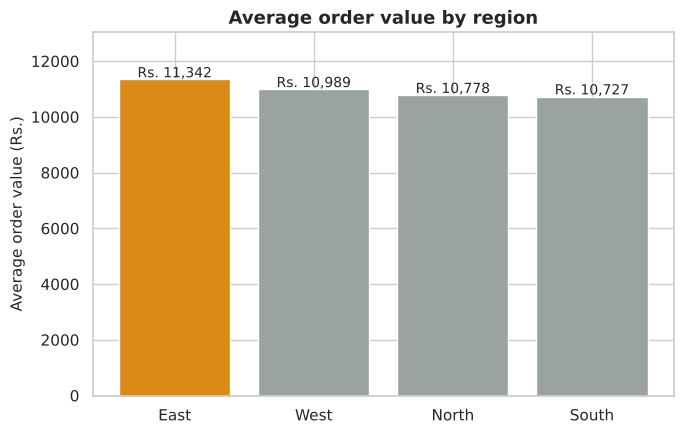

In [27]:
q1 = (df.groupby('Region')
        .agg(Orders=('Sales', 'size'), Total_Sales=('Sales', 'sum'), Avg_Order_Value=('Sales', 'mean'), Median_Order=('Sales', 'median'))
        .sort_values('Avg_Order_Value', ascending=False))
display(q1.round(0))

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = [AMBER if r == q1.index[0] else GREY for r in q1.index]
ax.bar(q1.index, q1.Avg_Order_Value, color=colors)
for i, v in enumerate(q1.Avg_Order_Value):
    ax.text(i, v + 80, f'Rs. {v:,.0f}', ha='center', fontsize=10)
ax.set_title('Average order value by region')
ax.set_ylabel('Average order value (Rs.)')
ax.set_ylim(0, q1.Avg_Order_Value.max() * 1.15)
plt.tight_layout()
keep_chart('Average order value by region. East is the highest and South the lowest.')
plt.show()

**Implication:** East has the highest average order value (about Rs. 11,300) and the highest total sales; South is lowest (about Rs. 10,700). The gap is only about 6%, so the regions are fairly similar and there is no region that needs rescue. East can be used as the benchmark.

**Q2. Which product category earns the most, and which has the lowest profit margin?**

                  Orders   Total_Sales  Total_Profit  Avg_Order_Value  Profit_Margin_pct  Sales_Share_pct
Product_Category                                                                                         
Electronics         1975 37,639,557.40 12,352,219.50        19,058.00              32.80            49.10
Furniture            979 26,057,893.90  8,547,604.80        26,616.80              32.80            34.00
Clothing            1533  7,781,680.40  2,521,027.80         5,076.10              32.40            10.10
Grocery             1669  2,685,875.10    874,840.20         1,609.30              32.60             3.50
Office Supplies      844  2,566,182.50    832,190.40         3,040.50              32.40             3.30


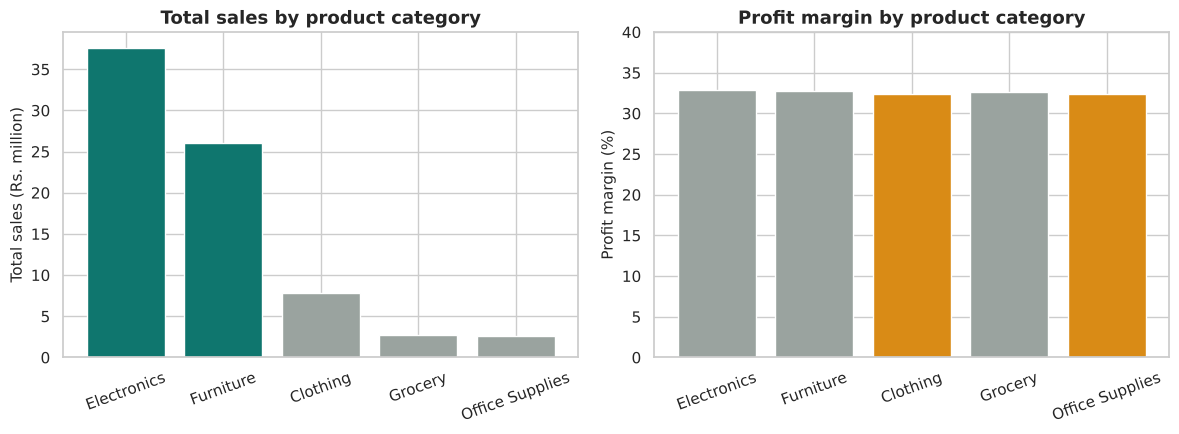

In [28]:
q2 = (df.groupby('Product_Category')
        .agg(Orders=('Sales', 'size'), Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum'), Avg_Order_Value=('Sales', 'mean'))
        .assign(Profit_Margin_pct=lambda t: t.Total_Profit / t.Total_Sales * 100,
                Sales_Share_pct=lambda t: t.Total_Sales / t.Total_Sales.sum() * 100)
        .sort_values('Total_Sales', ascending=False))
display(q2.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(q2.index, q2.Total_Sales / 1e6, color=[TEAL if i < 2 else GREY for i in range(len(q2))])
axes[0].set_title('Total sales by product category')
axes[0].set_ylabel('Total sales (Rs. million)')
axes[0].tick_params(axis='x', rotation=20)
low_margin = q2.Profit_Margin_pct.round(1) == q2.Profit_Margin_pct.round(1).min()
axes[1].bar(q2.index, q2.Profit_Margin_pct, color=[AMBER if low_margin[i] else GREY for i in q2.index])
axes[1].set_title('Profit margin by product category')
axes[1].set_ylabel('Profit margin (%)')
axes[1].set_ylim(0, 40)
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
keep_chart('Total sales and profit margin by product category. Electronics and Furniture bring most of the sales; margins are almost equal.')
plt.show()

**Implication:** Electronics (about Rs. 3.8 crore) and Furniture (about Rs. 2.6 crore) together bring about 83% of all sales, even though Furniture is only 14% of the orders. A Furniture order is worth about 16 times a Grocery order. Margins are almost equal across categories (32% to 33%); the lowest are Clothing and Office Supplies at about 32.4% (against 32.8% for Electronics), a difference too small to act on. So profit follows sales, and protecting Electronics and Furniture matters most.

**Q3. How do the customer segments compare?**

In [29]:
q3 = (df.groupby('Customer_Segment')
        .agg(Orders=('Sales', 'size'), Customers=('Customer_ID', 'nunique'), Total_Sales=('Sales', 'sum'),
             Total_Profit=('Profit', 'sum'), Avg_Order_Value=('Sales', 'mean'))
        .assign(Sales_Share_pct=lambda t: t.Total_Sales / t.Total_Sales.sum() * 100))
display(q3.round(1))

                  Orders  Customers   Total_Sales  Total_Profit  Avg_Order_Value  Sales_Share_pct
Customer_Segment                                                                                 
Consumer            3840       1437 41,718,896.30 13,703,577.40        10,864.30            54.40
Corporate           2114       1186 23,551,202.50  7,665,257.90        11,140.60            30.70
Home Office         1046        796 11,461,090.50  3,759,047.40        10,957.10            14.90


**Implication:** Corporate customers place only 30% of orders but have the highest average order value (about Rs. 11,100 vs Rs. 10,900 for Consumers), so a corporate account programme is worth testing. Still, Consumers bring 54% of sales through volume, so they remain the core base.

**Q4. Does a faster delivery mode actually deliver faster?**

In [30]:
q4 = (df.groupby('Delivery_Mode')
        .agg(Orders=('Sales', 'size'), Avg_Delivery_Days=('Delivery_Days', 'mean'),
             Median_Delivery_Days=('Delivery_Days', 'median'), Avg_Rating=('Customer_Rating', 'mean'))
        .reindex(['Same-Day', 'Express', 'Standard']))
display(q4.round(2))

               Orders  Avg_Delivery_Days  Median_Delivery_Days  Avg_Rating
Delivery_Mode                                                             
Same-Day          696               5.77                  6.00        3.12
Express          2055               5.63                  6.00        3.11
Standard         4249               5.65                  6.00        3.08


**Implication:** this is a red flag. **Same-Day** orders take on average 5.8 days, the same as **Standard** (5.7) and **Express** (5.6). The faster modes are not faster in practice, so if customers pay extra for them, the promise is not being kept. Ratings are also the same (about 3.1) across modes.

**Q5. Do bigger discounts reduce margin or change returns?**

In [31]:
q5 = (df.groupby('Discount_Band')
        .agg(Orders=('Sales', 'size'), Profit_Margin_pct=('Profit', 'sum'), Sales=('Sales', 'sum'),
             Return_Rate_pct=('Returned', lambda s: (s == 'Yes').mean() * 100), Avg_Rating=('Customer_Rating', 'mean')))
q5['Profit_Margin_pct'] = q5.Profit_Margin_pct / q5.Sales * 100
display(q5.drop(columns='Sales').round(2))

               Orders  Profit_Margin_pct  Return_Rate_pct  Avg_Rating
Discount_Band                                                        
0-10%            1668              32.94            12.95        3.09
10-20%           2329              32.67            11.29        3.11
20-30%           1679              32.64            14.29        3.05
30-50%           1324              32.73            12.16        3.12


**Implication:** in this data, the profit margin stays at about 33% whatever the discount level (0-10% up to 30-50%), and the return rate (11% to 14%) and rating show no clear trend with discount. So the data gives **no evidence that discounts hurt the margin** here. But note that 19% of orders carry a 30%+ discount, so it is worth checking with finance whether *Cost* already moves with the discount, before concluding that discounts are free.

**Q6. Are returned orders linked to unhappy customers?**

In [32]:
q6 = (df.groupby('Returned')
        .agg(Orders=('Sales', 'size'), Avg_Rating=('Customer_Rating', 'mean'),
             Low_Satisfaction_pct=('Satisfaction_Level', lambda s: (s == 'Low').mean() * 100)))
display(q6.round(2))
print('Overall return rate: %.1f%%' % ((df.Returned == 'Yes').mean() * 100))
print(df.groupby('Product_Category').Returned.apply(lambda s: (s == 'Yes').mean() * 100).round(1).to_dict())

          Orders  Avg_Rating  Low_Satisfaction_pct
Returned                                          
No          6120        3.23                 20.95
Yes          880        2.14                 54.09
Overall return rate: 12.6%
{'Clothing': 13.5, 'Electronics': 12.1, 'Furniture': 13.2, 'Grocery': 12.5, 'Office Supplies': 11.5}


**Implication:** this is the clearest pattern in the data. Returned orders have an average rating of about 2.1 versus 3.2 for kept orders, and a much higher share of Low satisfaction. About 1 in 8 orders (12.6%) is returned. Returns are similar across categories (about 11% to 14%), so the cause is likely not a specific product, but delivery or product quality in general.

**Q7. How do sales move over time?**

            Orders         Sales        Profit
Order_Year                                    
2023          3525 38,655,639.00 12,509,509.00
2024          3475 38,075,550.00 12,618,373.00


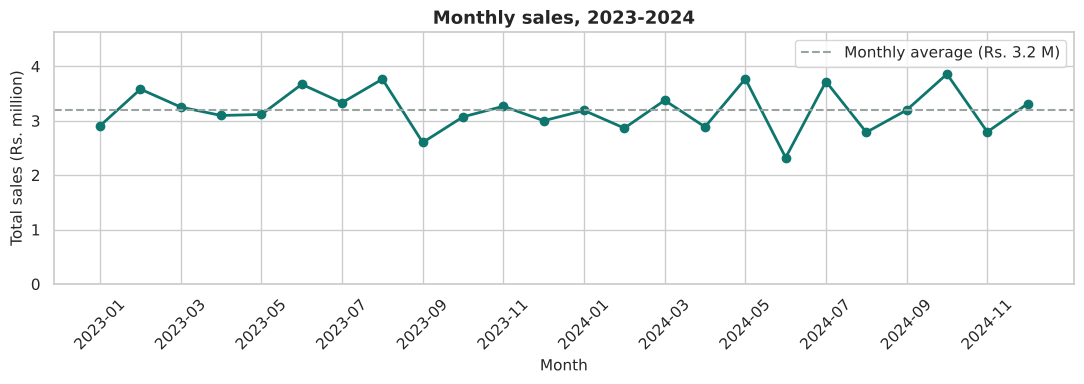

In [33]:
yearly = df.groupby('Order_Year').agg(Orders=('Sales', 'size'), Sales=('Sales', 'sum'), Profit=('Profit', 'sum'))
display(yearly.round(0))

monthly = df.groupby('Order_Month').Sales.sum() / 1e6
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly.values, marker='o', color=TEAL, lw=2)
ax.axhline(monthly.mean(), color=GREY, ls='--', label=f'Monthly average (Rs. {monthly.mean():.1f} M)')
ax.set_title('Monthly sales, 2023-2024')
ax.set_ylabel('Total sales (Rs. million)')
ax.set_xlabel('Month')
ax.set_xticks(range(0, len(monthly), 2))
ax.set_xticklabels(monthly.index[::2], rotation=45)
ax.set_ylim(0, monthly.max() * 1.2)
ax.legend()
plt.tight_layout()
keep_chart('Monthly sales, 2023 to 2024. Sales move in a narrow band with no clear season.')
plt.show()

**Implication:** sales are flat. 2024 sales are about 1.5% below 2023, and monthly sales move within a narrow band (about Rs. 5.8 to 7.1 million) with no repeating seasonal pattern. The business is stable but not growing, and this data alone does not justify a special seasonal stock plan.

**Q8. How concentrated is revenue among customers?**

In [34]:
cust = df.groupby('Customer_ID').agg(Orders=('Sales', 'size'), Revenue=('Sales', 'sum')).sort_values('Revenue', ascending=False)
top20 = cust.head(int(len(cust) * 0.2)).Revenue.sum() / cust.Revenue.sum()
print(f'Customers: {len(cust):,} | average orders per customer: {cust.Orders.mean():.1f} | average revenue per customer: Rs. {cust.Revenue.mean():,.0f}')
print(f'Top 20% of customers bring {top20:.0%} of total sales')
display(cust.head(5).round(0))

Customers: 1,576 | average orders per customer: 4.4 | average revenue per customer: Rs. 48,687
Top 20% of customers bring 45% of total sales
             Orders    Revenue
Customer_ID                   
CUST11430         8 254,002.00
CUST10354        11 238,065.00
CUST10459        14 221,691.00
CUST10302         9 219,115.00
CUST10970         6 218,119.00


**Implication:** about 1,576 customers placed 4.4 orders each on average. The top 20% of customers bring about 45% of sales. That is a moderate concentration, well below the classic 80/20 pattern, so the business is not dangerously dependent on a few buyers.

## 7. Save Cleaned Data and Summary of Findings

In [35]:
# Keep the helper flag columns so every cleaning decision stays traceable
df_out = df.copy()
df_out['Order_Date'] = df_out.Order_Date.dt.strftime('%Y-%m-%d')
df_out['Delivery_Date'] = df_out.Delivery_Date.dt.strftime('%Y-%m-%d')
df_out.to_csv(CLEAN_FILE, index=False)
print('Saved cleaned dataset:', df_out.shape[0], 'rows x', df_out.shape[1], 'columns')

Saved cleaned dataset: 7000 rows x 36 columns


### Summary: most important findings
1. **Data quality:** 7,084 rows contained 84 duplicates, 4 date formats, 12 region and 8 gender spellings, 12 impossible Age/Discount values and 9 income errors. After cleaning there are 7,000 unique, consistent transactions.
2. **Typical vs average order:** the typical (median) order is about Rs. 4,800, but the average is Rs. 10,960 because of a small number of large Electronics and Furniture orders.
3. **Where the money is:** Electronics and Furniture bring about 83% of sales; Grocery and Office Supplies together bring under 7%.
4. **Margins are uniform:** profit margin is about 33% in every category, region and discount band, so profit follows sales.
5. **Regions and years are stable:** East is slightly ahead (about 6% higher average order than South); 2024 is about 1.5% below 2023.
6. **Delivery promise is not kept:** Same-Day and Express orders take as long as Standard (about 5.7 days).
7. **Returns signal unhappy customers:** 12.6% of orders are returned and these have an average rating of 2.1 versus 3.2.

## 8. Test Cases (Checking that my code and my cleaned data are correct)

Cleaning code can have silent bugs, so I write **automated test cases** using Python's built-in `unittest` module. The tests are grouped by the library they check:

| Group | Library | What is tested |
|---|---|---|
| A | **pandas** | row count, uniqueness, labels, data types, missing values, Profit = Sales - Cost |
| B | **numpy** | valid ranges, finite numbers, Sales formula, income errors gone |
| C | **datetime / pandas** | date parsing function and delivery-day logic |
| D | **my own functions** | `full_describe` and `outlier_report` on tiny data where I know the answer |
| E | **feature engineering** | calculated columns match a manual calculation |
| F | **matplotlib / seaborn and file I/O** | charts were created, cleaned CSV reloads correctly |

If every test says `ok`, the cleaning did what I claimed in Section 3.

In [36]:
import sys
import unittest

CORE_COLS = ['Transaction_ID', 'Customer_ID', 'Order_Date', 'Age', 'Gender', 'Income', 'Region', 'Customer_Segment',
             'Product_Category', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Satisfaction_Level', 'Returned']

class TestCleanedRetailData(unittest.TestCase):

    # ---------- A. pandas ----------
    def test_A1_pandas_row_count_after_removing_duplicates(self):
        self.assertEqual(len(df), 7000)

    def test_A2_pandas_raw_data_is_untouched(self):
        self.assertEqual(raw.shape, (7084, 24))

    def test_A3_pandas_transaction_id_is_unique(self):
        self.assertTrue(df.Transaction_ID.is_unique)

    def test_A4_pandas_no_duplicate_rows(self):
        self.assertEqual(df.duplicated().sum(), 0)

    def test_A5_pandas_gender_labels_standardised(self):
        self.assertEqual(set(df.Gender), {'Male', 'Female'})

    def test_A6_pandas_region_labels_standardised(self):
        self.assertEqual(set(df.Region), {'North', 'South', 'East', 'West'})

    def test_A7_pandas_date_columns_are_datetime(self):
        self.assertTrue(pd.api.types.is_datetime64_any_dtype(df.Order_Date))
        self.assertTrue(pd.api.types.is_datetime64_any_dtype(df.Delivery_Date))

    def test_A8_pandas_no_missing_values_in_core_columns(self):
        self.assertEqual(int(df[CORE_COLS].isna().sum().sum()), 0)

    def test_A9_pandas_profit_equals_sales_minus_cost(self):
        pd.testing.assert_series_equal((df.Sales - df.Cost).round(2), df.Profit.round(2), check_names=False)

    # ---------- B. numpy ----------
    def test_B1_numpy_age_in_valid_range(self):
        ages = df.Age.to_numpy()
        self.assertTrue(np.all((ages >= 18) & (ages <= 100)))

    def test_B2_numpy_discount_between_0_and_half(self):
        d = df.Discount.to_numpy()
        self.assertTrue(np.all((d >= 0) & (d <= 0.5)))

    def test_B3_numpy_sales_formula_holds(self):
        expected = (df.Quantity * df.Unit_Price * (1 - df.Discount)).to_numpy()
        np.testing.assert_allclose(df.Sales.to_numpy(), expected, rtol=0, atol=0.02)

    def test_B4_numpy_all_numbers_are_finite(self):
        self.assertTrue(np.isfinite(df[num_cols].to_numpy(dtype=float)).all())

    def test_B5_numpy_income_errors_are_gone(self):
        self.assertLess(df.Income.max(), 500_000)          # raw maximum was 17.5 lakh
        self.assertGreaterEqual(df.Income.min(), 15_000)

    # ---------- C. datetime ----------
    def test_C1_parse_mixed_date_reads_all_four_formats(self):
        samples = pd.Series(['2023-12-19', '19/12/2023', '12-19-2023', '19-Dec-2023'])
        parsed = parse_mixed_date(samples)
        self.assertTrue((parsed == pd.Timestamp(2023, 12, 19)).all())

    def test_C2_order_dates_inside_2023_2024(self):
        self.assertGreaterEqual(df.Order_Date.min(), pd.Timestamp('2023-01-01'))
        self.assertLessEqual(df.Order_Date.max(), pd.Timestamp('2024-12-31'))

    def test_C3_delivery_days_never_negative(self):
        self.assertGreaterEqual(df.Delivery_Days.min(), 0)

    # ---------- D. my own functions, tiny data with a known answer ----------
    def test_D1_full_describe_on_known_data(self):
        r = full_describe(pd.Series([1, 2, 3, 4, 5]))
        self.assertEqual(r['mean'], 3)
        self.assertEqual(r['median'], 3)
        self.assertEqual(r['IQR'], 2)

    def test_D2_outlier_report_finds_the_one_outlier(self):
        r = outlier_report(pd.Series([1, 2, 3, 4, 5, 6, 7, 8, 9, 100]))
        self.assertEqual(r['IQR outliers'], 1)

    def test_D3_outlier_report_finds_none_in_even_data(self):
        r = outlier_report(pd.Series([10, 11, 12, 13, 14, 15]))
        self.assertEqual(r['IQR outliers'], 0)

    # ---------- E. feature engineering ----------
    def test_E1_profit_margin_matches_manual_calculation(self):
        np.testing.assert_allclose(df.Profit_Margin, df.Profit / df.Sales)
        self.assertTrue(df.Profit_Margin.between(0, 1).all())

    def test_E2_delivery_days_matches_date_difference(self):
        row = df[df.Delivery_Date.notna()].iloc[0]
        self.assertEqual(row.Delivery_Days, (row.Delivery_Date - row.Order_Date).days)

    def test_E3_revenue_per_customer_matches_groupby_total(self):
        cust = df.Customer_ID.iloc[0]
        self.assertAlmostEqual(df[df.Customer_ID == cust].Revenue_per_Customer.iloc[0], df[df.Customer_ID == cust].Sales.sum(), places=2)

    # ---------- F. matplotlib / seaborn output and file I/O ----------
    def test_F1_charts_were_created(self):
        self.assertGreaterEqual(len(CHARTS), 7)
        for fig, caption in CHARTS:
            self.assertGreater(len(fig.axes), 0, msg='a chart is empty')
            self.assertGreater(len(caption), 10)

    def test_F2_cleaned_csv_reloads_correctly(self):
        back = pd.read_csv(CLEAN_FILE)
        self.assertEqual(back.shape, df.shape)
        self.assertEqual(set(back.Transaction_ID), set(df.Transaction_ID))

suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestCleanedRetailData)
result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
assert result.wasSuccessful(), 'Some tests failed, check the output above'

test_A1_pandas_row_count_after_removing_duplicates (builtins.TestCleanedRetailData.test_A1_pandas_row_count_after_removing_duplicates) ... ok
test_A2_pandas_raw_data_is_untouched (builtins.TestCleanedRetailData.test_A2_pandas_raw_data_is_untouched) ... ok
test_A3_pandas_transaction_id_is_unique (builtins.TestCleanedRetailData.test_A3_pandas_transaction_id_is_unique) ... ok
test_A4_pandas_no_duplicate_rows (builtins.TestCleanedRetailData.test_A4_pandas_no_duplicate_rows) ... ok
test_A5_pandas_gender_labels_standardised (builtins.TestCleanedRetailData.test_A5_pandas_gender_labels_standardised) ... ok
test_A6_pandas_region_labels_standardised (builtins.TestCleanedRetailData.test_A6_pandas_region_labels_standardised) ... ok
test_A7_pandas_date_columns_are_datetime (builtins.TestCleanedRetailData.test_A7_pandas_date_columns_are_datetime) ... ok
test_A8_pandas_no_missing_values_in_core_columns (builtins.TestCleanedRetailData.test_A8_pandas_no_missing_values_in_core_columns) ... ok
test_A9_pa

**Result:** all tests pass. This means the cleaned data has no duplicates or impossible values, the date parser reads all four formats the same way, the Sales and Profit formulas still hold after cleaning, and the saved files can be reloaded without loss. If I ever change the cleaning code, I can re-run this cell to catch mistakes immediately.

## 9. Fairness Check

**Question:** are some groups of customers treated differently? Before anyone uses this data for decisions, I compare **Gender, Age group, Region and Customer segment** on five things: average discount, share of big discounts (30% or more), average rating, return rate and delivery days.

**How I decide if a gap is real:** a Welch t-test (2 groups) or ANOVA (3 or more groups) for numbers, and a chi-square test for rates. A p-value below 0.05 means the gap is unlikely to be pure chance. I also use the **four-fifths rule**: the lowest group's "not returned" rate divided by the highest group's should stay above 0.80.

This check only looks at outcomes (what happened in the orders). It cannot say why.

In [37]:
from scipy import stats

fair = df.copy()          # work on a copy so the cleaned data stays as it is
fair['Age_Group'] = pd.cut(fair.Age, [17, 29, 44, 59, 100], labels=['18-29', '30-44', '45-59', '60+'])
fair['High_Discount'] = fair.Discount >= 0.30          # 30% or more counts as a big discount
fair['Is_Returned'] = fair.Returned == 'Yes'

def check_groups(col):
    """Compare the groups of one column and test if the gaps are real."""
    g = fair.groupby(col, observed=True)
    table = pd.DataFrame({
        'Orders': g.size(),
        'Avg_Discount_pct': g.Discount.mean() * 100,
        'High_Discount_pct': g.High_Discount.mean() * 100,
        'Avg_Rating': g.Customer_Rating.mean(),
        'Return_Rate_pct': g.Is_Returned.mean() * 100,
        'Avg_Delivery_Days': g.Delivery_Days.mean(),
    })
    parts = [x for _, x in fair.groupby(col, observed=True)]

    def numeric_test(metric):
        values = [x[metric].dropna() for x in parts]
        if len(values) == 2:
            return stats.ttest_ind(*values, equal_var=False).pvalue    # two groups: Welch t-test
        return stats.f_oneway(*values).pvalue                          # 3+ groups: ANOVA

    p = {
        'Avg_Discount_pct': numeric_test('Discount'),
        'Avg_Rating': numeric_test('Customer_Rating'),
        'Avg_Delivery_Days': numeric_test('Delivery_Days'),
        'Return_Rate_pct': stats.chi2_contingency(pd.crosstab(fair[col], fair.Is_Returned))[1],
        'High_Discount_pct': stats.chi2_contingency(pd.crosstab(fair[col], fair.High_Discount))[1],
    }
    not_returned = 100 - table.Return_Rate_pct
    ratio = not_returned.min() / not_returned.max()                    # four-fifths rule
    return table, p, ratio

all_p = {}
for col in ['Gender', 'Age_Group', 'Region', 'Customer_Segment']:
    table, p, ratio = check_groups(col)
    all_p[col] = p
    print('====', col, '====')
    display(table.round(2))
    print('p-values:', {k: round(float(v), 3) for k, v in p.items()})
    print('Four-fifths ratio (not returned):', round(ratio, 3), '-> passes' if ratio >= 0.8 else '-> FAILS')
    print()

n_tests = sum(len(p) for p in all_p.values())
small = [(c, m, round(float(v), 3)) for c, p in all_p.items() for m, v in p.items() if v < 0.05]
print('Tests run:', n_tests, '| p < 0.05:', small)
print('Expected by pure chance at the 5% level:', round(n_tests * 0.05, 1), '| Bonferroni limit:', round(0.05 / n_tests, 4))

old = fair[fair.Age_Group == '60+']
rate = old.Is_Returned.mean()
margin = 1.96 * np.sqrt(rate * (1 - rate) / len(old))
print('Age 60+: orders =', len(old), '| return rate = %.1f%% (95%% range %.1f%% to %.1f%%)' % (rate * 100, (rate - margin) * 100, (rate + margin) * 100))

==== Gender ====
        Orders  Avg_Discount_pct  High_Discount_pct  Avg_Rating  Return_Rate_pct  Avg_Delivery_Days
Gender                                                                                             
Female    3675             20.07              20.68        3.11            12.84               5.69
Male      3325             19.91              20.30        3.07            12.27               5.61
p-values: {'Avg_Discount_pct': 0.583, 'Avg_Rating': 0.129, 'Avg_Delivery_Days': 0.222, 'Return_Rate_pct': 0.493, 'High_Discount_pct': 0.717}
Four-fifths ratio (not returned): 0.993 -> passes

==== Age_Group ====
           Orders  Avg_Discount_pct  High_Discount_pct  Avg_Rating  Return_Rate_pct  Avg_Delivery_Days
Age_Group                                                                                             
18-29        1967             19.81              20.34        3.05            13.22               5.61
30-44        3618             20.05              20.78        

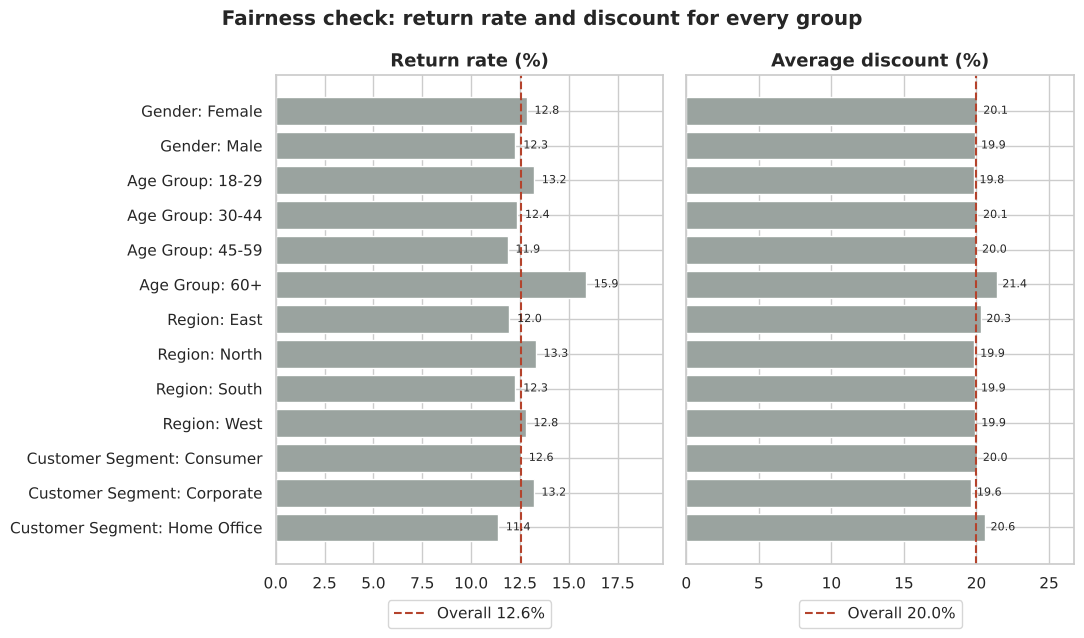

In [38]:
rows = []
for col in ['Gender', 'Age_Group', 'Region', 'Customer_Segment']:
    g = fair.groupby(col, observed=True).agg(ret=('Is_Returned', 'mean'), disc=('Discount', 'mean'))
    for name, r in g.iterrows():
        rows.append((col.replace('_', ' ') + ': ' + str(name), r.ret * 100, r.disc * 100))
plot = pd.DataFrame(rows, columns=['Group', 'Return rate (%)', 'Average discount (%)'])

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True)
for ax, col, overall in zip(axes, ['Return rate (%)', 'Average discount (%)'],
                            [fair.Is_Returned.mean() * 100, fair.Discount.mean() * 100]):
    ax.barh(plot.Group, plot[col], color=GREY)
    ax.axvline(overall, color=BRICK, ls='--', label=f'Overall {overall:.1f}%')
    ax.set_title(col)
    ax.set_xlim(0, plot[col].max() * 1.25)
    for i, v in enumerate(plot[col]):
        ax.text(v + 0.4, i, f'{v:.1f}', va='center', fontsize=8)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06))
axes[0].invert_yaxis()
plt.suptitle('Fairness check: return rate and discount for every group', fontweight='bold')
plt.tight_layout()
keep_chart('Return rate and average discount for every customer group. The dashed line is the overall value.')
plt.show()

**Reading:** no group is treated differently in a way that is more than chance. All four-fifths ratios are above 0.95 (the warning line is 0.80). Two small points:
- **Home Office rating** (3.18 vs 3.07 for Consumers) gives p = 0.011. That is the only result below 0.05, but I ran 20 tests, so about one such result is expected by luck. It also fails the stricter Bonferroni limit (0.0025).
- **Age 60+** has the highest return rate (15.9%) but only 126 orders, so its 95% range (about 9.5% to 22.3%) easily includes the overall 12.6%. The overall age test (p = 0.435) shows no real difference.

**Limit:** the data is simulated and very even, so a result like this is expected. This is a first check, not a proof of fairness.

### Save all charts in one PDF

In [39]:
from matplotlib.backends.backend_pdf import PdfPages

def save_charts_pdf(path):
    """Write every collected chart into one PDF, one chart per page, with its caption."""
    with PdfPages(path) as pdf:
        cover = plt.figure(figsize=(8.27, 4))
        cover.text(0.5, 0.62, 'Charts: Retail Customer Sales EDA', ha='center', fontsize=20, fontweight='bold', color=TEAL)
        cover.text(0.5, 0.45, 'Abhishek Sharma  |  ID 2026M01410110', ha='center', fontsize=12)
        cover.text(0.5, 0.33, str(len(CHARTS)) + ' charts, one per page', ha='center', fontsize=10, color=GREY)
        pdf.savefig(cover)
        plt.close(cover)
        for number, (fig, caption) in enumerate(CHARTS, 1):
            fig.text(0.5, -0.03, 'Chart ' + str(number) + '. ' + caption, ha='center', va='top',
                     fontsize=9, style='italic', color='#555555', wrap=True)
            pdf.savefig(fig, bbox_inches='tight')

save_charts_pdf(CHARTS_FILE)
print('Saved', len(CHARTS), 'charts in one PDF:', CHARTS_FILE)

Saved 9 charts in one PDF: ../09_Charts/Abhishek_sharma_2026M01410110_Charts.pdf


## 10. Final Conclusion (in simple words)

**What I did.** I took a dirty file of 7,084 retail transactions, checked it for six kinds of problems, cleaned it step by step, and then tested my own cleaning with automated test cases. Only after that did I look at what the business is actually doing.

**What I found about the data.** The file was messy, but most problems could be fixed with *evidence* and not guesses. For example, a customer's age and income do not change from one order to the next, so a wrong or missing value could be copied from the same customer's other orders. A wrong discount could be rebuilt from the Sales formula. Where nothing reliable existed (a customer's rating, a delivery date), I kept the blank instead of inventing a number.

**What I found about the business.** It is steady: about Rs. 7.7 crore in sales and Rs. 2.5 crore in profit, a 33% margin, with almost no change from 2023 to 2024. A normal order is only about Rs. 4,800, but a small number of big Electronics and Furniture orders bring most of the money (83% of sales together).

**Two things that worry me.**
1. Same-Day and Express delivery take about as long as Standard (around 5.7 days). If customers pay extra for speed, that promise is not being kept.
2. About 1 in 8 orders (12.6%) is returned, and these customers give much lower ratings (2.1 vs 3.2). Returns are spread over every category, so the cause is probably something general like delivery or quality, not one product.

**Fairness.** I also checked whether gender, age group, region or customer segment get different discounts, ratings, returns or delivery times. I found no real difference. The two small points (Home Office ratings, and the small 60+ group) are most likely chance.

**What I am not sure about.**
- This is a simulated dataset and its patterns are very even, so small gaps (for example East being about 6% ahead of South) may be just chance. EDA can show a difference, but only a statistical test (Project 3) can say whether it is real.
- The margin did not fall with higher discounts, which is unusual in real shops. I would ask finance whether *Cost* already changes with the discount before trusting that result.

**What I would do next.** Fix or stop selling the faster delivery modes, ask returning customers why they returned, report medians next to averages, and run proper hypothesis tests on the regional and segment differences.

**What I learned.** A good analyst spends more time understanding and checking the data than calculating on it. Writing down every cleaning decision and testing it made me trust the final numbers, and the median told me the truth about a typical order where the average did not.